# ECS 171 — DNN Random Initialization + SGD, Random Initilization + Adam Hyperparameter Tuning

This notebook performs **random search** over learning rate, batch size, hidden-layer count, and neurons per hidden layer. Every sampled configuration is trained with **both SGD and Adam**.

**Selection rule:** highest validation AUC. The test set is held out until the two optimizer-specific finalists have been selected.

This notebook reproduces the preprocessing used in the initial notebook: the three processed CSV files, `HeartDisease` as the target, and `StandardScaler` fit on training data only.

## 1. Imports and reproducibility

In [79]:
import copy
import itertools
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, recall_score
from IPython.display import display
import os

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 2. Load the same processed datasets

These paths and target column match the uploaded initial notebook. If you are using Google Colab, make sure the three CSV files are available at these paths. If they are in a different folder, change only the paths below.

In [80]:
TRAIN_PATH = "/content/heart_train_processed.csv"
VAL_PATH   = "/content/heart_val_processed.csv"
TEST_PATH  = "/content/heart_test_processed.csv"

TARGET_COLUMN = "HeartDisease"

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

display(train_df.head())

Train: (587, 17)
Validation: (147, 17)
Test: (184, 17)


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,Chol_missing,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up,HeartDisease
0,0.439478,1,-1.386657,-0.839102,0,-1.031459,0,-0.911046,0,0,0,0,1,0,1,0,1
1,-1.308144,0,-1.241787,0.560352,0,1.408013,1,-0.911046,0,0,1,0,0,0,0,1,0
2,0.222642,1,-0.083689,-0.725996,1,-1.472717,0,0.741291,0,0,0,0,1,0,1,0,1
3,1.564185,0,-0.696869,-0.549930,0,-0.844282,0,0.741291,0,0,1,0,0,0,1,0,0
4,-0.202447,1,1.416269,1.571399,0,-1.617169,1,1.401569,0,0,0,0,1,0,1,0,1


## 3. Preprocess data exactly as in the initial notebook

The scaler is fitted on the training features only, then applied unchanged to validation and test features. We also check that feature columns match across all three splits.

In [81]:
X_train = train_df.drop(columns=[TARGET_COLUMN])
y_train = train_df[TARGET_COLUMN]

X_val = val_df.drop(columns=[TARGET_COLUMN])
y_val = val_df[TARGET_COLUMN]

X_test = test_df.drop(columns=[TARGET_COLUMN])
y_test = test_df[TARGET_COLUMN]

# Keep validation/test columns in exactly the training feature order
X_val = X_val[X_train.columns]
X_test = X_test[X_train.columns]

# Check binary labels and ensure both classes exist in each split
for split_name, labels in [
    ("train", y_train), ("validation", y_val), ("test", y_test)
]:
    unique_labels = set(pd.Series(labels).dropna().unique())
    if not unique_labels.issubset({0, 1}):
        raise ValueError(
            f"{split_name} labels must be encoded as 0/1; found {unique_labels}"
        )
    if len(unique_labels) != 2:
        raise ValueError(
            f"{split_name} split must contain both classes for ROC AUC."
        )

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(
    np.asarray(y_train).reshape(-1, 1), dtype=torch.float32
)
y_val_tensor = torch.tensor(
    np.asarray(y_val).reshape(-1, 1), dtype=torch.float32
)
y_test_tensor = torch.tensor(
    np.asarray(y_test).reshape(-1, 1), dtype=torch.float32
)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

input_size = X_train_tensor.shape[1]

print("Number of input features:", input_size)
print("Train / validation / test:", len(train_dataset), len(val_dataset), len(test_dataset))

Number of input features: 16
Train / validation / test: 587 147 184


## 4. Define the model and evaluation functions

The architecture preserves the original design: Sigmoid after each hidden layer and after the one-unit output layer, Xavier Uniform weights, zero biases, and binary cross-entropy loss.

In [82]:
class NeuralNetwork(nn.Module):
    def __init__(self, input_size, hidden_layers, neurons):
        super().__init__()

        layers = []
        previous_size = input_size

        for _ in range(hidden_layers):
            linear = nn.Linear(previous_size, neurons)

             # Paper's standard random initialization (Equation 1)
            nn.init.uniform_(
                linear.weight,
                -1 / (previous_size ** 0.5),
                 1 / (previous_size ** 0.5)
            )

            nn.init.zeros_(linear.bias)
            layers.extend([linear, nn.Sigmoid()])
            previous_size = neurons

        output = nn.Linear(previous_size, 1)

         # Paper's standard random initialization (Equation 1)
        nn.init.uniform_(
              output.weight,
                -1 / (previous_size ** 0.5),
                 1 / (previous_size ** 0.5)
)

        nn.init.zeros_(output.bias)

        layers.extend([output, nn.Sigmoid()])
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def evaluate_model(model, loader):
    model.eval()
    probabilities = []
    targets = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            probs = model(X_batch).cpu().numpy().ravel()

            probabilities.extend(probs)
            targets.extend(y_batch.numpy().ravel())

    probabilities = np.asarray(probabilities)
    targets = np.asarray(targets).astype(int)
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "AUC": roc_auc_score(targets, probabilities),
        "Accuracy": accuracy_score(targets, predictions),
        "Recall": recall_score(targets, predictions, zero_division=0)
    }


criterion = nn.BCELoss()

## 5. Configure random search

We will sample 20 unique configurations from the full search space (216 combinations). Each configuration is tested with both optimizers, for **40 model runs maximum**.

We keep the optimizer list fixed at SGD and Adam. The other search dimensions are:
- Learning rate: 0.0001, 0.001, 0.01
- Batch size: 16, 32, 64
- Hidden layers: 1 through 6
- Neurons per hidden layer: 8, 16, 32, 64

The same neuron count is used in each hidden layer within a trial, matching the simple architecture family from the initial experiment.

In [83]:
LEARNING_RATES = [0.0001, 0.001, 0.01]
BATCH_SIZES = [16, 32, 64]
HIDDEN_LAYER_OPTIONS = [1, 2, 3, 4, 5, 6]
NEURON_OPTIONS = [8, 16, 32, 64]

OPTIMIZERS_TO_TEST = ["SGD", "Adam"]

N_CONFIGURATIONS = 20
MAX_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 15

all_configurations = list(itertools.product(
    LEARNING_RATES,
    BATCH_SIZES,
    HIDDEN_LAYER_OPTIONS,
    NEURON_OPTIONS
))

search_rng = random.Random(SEED)
sampled_configurations = search_rng.sample(
    all_configurations,
    k=min(N_CONFIGURATIONS, len(all_configurations))
)

config_df = pd.DataFrame(
    sampled_configurations,
    columns=["Learning Rate", "Batch Size", "Hidden Layers", "Neurons"]
)
config_df.insert(0, "Configuration", range(1, len(config_df) + 1))

print(f"Total possible configurations: {len(all_configurations)}")
print(f"Configurations sampled: {len(config_df)}")
print(f"Expected model runs: {len(config_df) * len(OPTIMIZERS_TO_TEST)}")
display(config_df)

Total possible configurations: 216
Configurations sampled: 20
Expected model runs: 40


,Configuration,Learning Rate,Batch Size,Hidden Layers,Neurons
0,1,0.0100,16,5,64
1,2,0.0001,32,2,8
2,3,0.0001,16,2,32
3,4,0.0100,32,6,16
4,5,0.0001,64,6,32
5,6,0.0001,64,4,32
6,7,0.0001,64,3,16
7,8,0.0001,32,3,64
8,9,0.0100,32,6,8
9,10,0.0001,32,1,32


## 6. Training function with validation-AUC checkpointing and early stopping

Validation AUC is checked once per epoch. The model checkpoint with the highest validation AUC is restored. Early stopping ends a run if validation AUC has not improved for 15 consecutive epochs, up to a maximum of 100 epochs.

For a fair optimizer comparison within each sampled configuration, SGD and Adam receive identical initial weights and identically seeded shuffled training loaders.

In [84]:
def get_gradient_norms(model):
    """
    Calculate the L2 gradient norm for each Linear layer.
    """
    gradient_norms = {}

    layer_number = 1

    for module in model.modules():

        if isinstance(module, nn.Linear):

            if module.weight.grad is not None:

                gradient_norm = module.weight.grad.norm(2).item()

                gradient_norms[f"layer_{layer_number}"] = gradient_norm

            layer_number += 1

    return gradient_norms

In [85]:

def train_one_trial(
    model,
    train_loader,
    val_loader,
    optimizer,
    max_epochs=MAX_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE
):
    best_val_auc = -np.inf
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "val_auc": [],
        "gradient_norms": []
    }

    start_time = time.time()

    for epoch in range(max_epochs):

        model.train()
        total_loss = 0.0

        # Initialize gradient tracking for this epoch
        epoch_gradient_norms = []

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            probabilities = model(X_batch)

            loss = criterion(probabilities, y_batch)

            loss.backward()

            # ==================================
            # GRADIENT MONITORING
            # ==================================

            batch_gradient_norms = get_gradient_norms(model)

            epoch_gradient_norms.append(batch_gradient_norms)

            # Update weights
            optimizer.step()

            total_loss += loss.item() * X_batch.size(0)

        epoch_train_loss = total_loss / len(train_loader.dataset)

        val_metrics = evaluate_model(model, val_loader)

        val_auc = val_metrics["AUC"]

        # Store training history
        history["train_loss"].append(epoch_train_loss)
        history["val_auc"].append(val_auc)
        history["gradient_norms"].append(epoch_gradient_norms)

        # Early stopping and best model tracking
        if val_auc > best_val_auc + 1e-6:

            best_val_auc = val_auc
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    elapsed_time = time.time() - start_time

    if best_state is None:
        raise RuntimeError("No valid best model checkpoint was saved.")

    model.load_state_dict(best_state)

    return model, history, best_val_auc, best_epoch, elapsed_time


## 7. Run random search: every configuration with both SGD and Adam

This is the main compute-heavy cell. It stores each run's best validation checkpoint and summary metrics. It does **not** evaluate the test set during the search.

In [69]:
tuning_results = []
best_models = {}
tuning_histories = {}

for _, row in config_df.iterrows():
    config_id = int(row["Configuration"])
    learning_rate = float(row["Learning Rate"])
    batch_size = int(row["Batch Size"])
    hidden_layers = int(row["Hidden Layers"])
    neurons = int(row["Neurons"])

    print(
        f"\nConfig {config_id}/{len(config_df)} | "
        f"lr={learning_rate}, batch={batch_size}, "
        f"layers={hidden_layers}, neurons={neurons}"
    )

    # Initialize once per configuration; both optimizers start from these same weights.
    torch.manual_seed(SEED + config_id)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED + config_id)

    initial_model = NeuralNetwork(
        input_size=input_size,
        hidden_layers=hidden_layers,
        neurons=neurons
    ).to(device)
    initial_state = copy.deepcopy(initial_model.state_dict())

    for optimizer_name in OPTIMIZERS_TO_TEST:
        model = NeuralNetwork(
            input_size=input_size,
            hidden_layers=hidden_layers,
            neurons=neurons
        ).to(device)
        model.load_state_dict(initial_state)

        # Identical shuffle sequence for SGD and Adam within this configuration.
        train_generator = torch.Generator()
        train_generator.manual_seed(SEED + 1000 + config_id)

        train_loader_trial = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True,
            generator=train_generator
        )
        val_loader_trial = DataLoader(
            val_dataset,
            batch_size=batch_size,
            shuffle=False
        )

        if optimizer_name == "SGD":
            optimizer = optim.SGD(model.parameters(), lr=learning_rate)
        else:
            optimizer = optim.Adam(model.parameters(), lr=learning_rate)

        model, history, best_val_auc, best_epoch, elapsed = train_one_trial(
            model,
            train_loader_trial,
            val_loader_trial,
            optimizer
        )

        train_metrics = evaluate_model(model, train_loader_trial)
        val_metrics = evaluate_model(model, val_loader_trial)

        run_key = (config_id, optimizer_name)
        best_models[run_key] = copy.deepcopy(model)
        tuning_histories[run_key] = history

        tuning_results.append({
            "Configuration": config_id,
            "Optimizer": optimizer_name,
            "Learning Rate": learning_rate,
            "Batch Size": batch_size,
            "Hidden Layers": hidden_layers,
            "Neurons": neurons,
            "Best Epoch": best_epoch,
            "Epochs Run": len(history["val_auc"]),
            "Training Time (sec)": elapsed,
            "Train AUC": train_metrics["AUC"],
            "Validation AUC": val_metrics["AUC"],
            "Train Accuracy": train_metrics["Accuracy"],
            "Validation Accuracy": val_metrics["Accuracy"],
            "Train Recall": train_metrics["Recall"],
            "Validation Recall": val_metrics["Recall"]
        })

        print(
            f"  {optimizer_name}: val AUC={val_metrics['AUC']:.4f}, "
            f"best epoch={best_epoch}, time={elapsed:.1f}s"
        )

print("\nRandom search completed.")


Config 1/20 | lr=0.01, batch=16, layers=5, neurons=64
  SGD: val AUC=0.7737, best epoch=99, time=6.7s
  Adam: val AUC=0.9302, best epoch=1, time=1.4s

Config 2/20 | lr=0.0001, batch=32, layers=2, neurons=8
  SGD: val AUC=0.7333, best epoch=10, time=0.7s
  Adam: val AUC=0.9340, best epoch=49, time=2.4s

Config 3/20 | lr=0.0001, batch=16, layers=2, neurons=32
  SGD: val AUC=0.7331, best epoch=4, time=1.7s
  Adam: val AUC=0.9366, best epoch=27, time=2.8s

Config 4/20 | lr=0.01, batch=32, layers=6, neurons=16
  SGD: val AUC=0.2389, best epoch=1, time=0.6s
  Adam: val AUC=0.9390, best epoch=1, time=0.8s

Config 5/20 | lr=0.0001, batch=64, layers=6, neurons=32
  SGD: val AUC=0.7863, best epoch=22, time=0.9s
  Adam: val AUC=0.9308, best epoch=91, time=3.5s

Config 6/20 | lr=0.0001, batch=64, layers=4, neurons=32
  SGD: val AUC=0.3444, best epoch=70, time=2.0s
  Adam: val AUC=0.9342, best epoch=95, time=4.2s

Config 7/20 | lr=0.0001, batch=64, layers=3, neurons=16
  SGD: val AUC=0.7318, best 

## 8. Review and save all tuning results

The table is sorted by validation AUC. Do not use test metrics to choose a configuration.

In [70]:
tuning_df = pd.DataFrame(tuning_results).sort_values(
    "Validation AUC", ascending=False
).reset_index(drop=True)

display(tuning_df.round(4))

tuning_df.to_csv("hyperparameter_search_results.csv", index=False)
config_df.to_csv("random_search_configurations.csv", index=False)

print("Saved hyperparameter_search_results.csv")
print("Saved random_search_configurations.csv")

,Configuration,Optimizer,Learning Rate,Batch Size,Hidden Layers,Neurons,Best Epoch,Epochs Run,Training Time (sec),Train AUC,Validation AUC,Train Accuracy,Validation Accuracy,Train Recall,Validation Recall
0,15,Adam,0.0010,32,4,8,3,18,0.7273,0.9046,0.9413,0.4463,0.4490,0.0000,0.0000
1,4,Adam,0.0100,32,6,16,1,16,0.7915,0.9210,0.9390,0.5537,0.5510,1.0000,1.0000
2,11,Adam,0.0100,32,2,16,1,16,0.5384,0.9171,0.9366,0.7496,0.7687,0.9785,0.9753
3,3,Adam,0.0001,16,2,32,27,42,2.8137,0.9200,0.9366,0.6848,0.6599,1.0000,1.0000
4,7,Adam,0.0001,64,3,16,72,87,2.1831,0.9160,0.9360,0.5537,0.5510,1.0000,1.0000
5,16,Adam,0.0001,16,3,8,30,45,3.5523,0.9153,0.9343,0.5537,0.5510,1.0000,1.0000
6,6,Adam,0.0001,64,4,32,95,100,4.1662,0.9214,0.9342,0.5537,0.5510,1.0000,1.0000
7,19,Adam,0.0001,64,2,64,52,67,1.4683,0.9200,0.9342,0.8416,0.8707,0.9508,0.9259
8,2,Adam,0.0001,32,2,8,49,64,2.4151,0.9129,0.9340,0.7121,0.7279,0.5108,0.5185
9,12,Adam,0.0010,64,5,64,12,27,0.9628,0.9231,0.9340,0.8654,0.8776,0.8985,0.8642


Saved hyperparameter_search_results.csv
Saved random_search_configurations.csv


## 9. Select the best SGD and Adam configurations

We select one best configuration for each optimizer, using validation AUC only. This preserves the planned SGD-versus-Adam comparison.

In [71]:
best_rows = (
    tuning_df.sort_values("Validation AUC", ascending=False)
    .groupby("Optimizer", as_index=False)
    .first()
)

display(best_rows.round(4))

best_sgd_row = (
    tuning_df[tuning_df["Optimizer"] == "SGD"]
    .sort_values("Validation AUC", ascending=False)
    .iloc[0]
)
best_adam_row = (
    tuning_df[tuning_df["Optimizer"] == "Adam"]
    .sort_values("Validation AUC", ascending=False)
    .iloc[0]
)

print("Best SGD validation AUC:", round(best_sgd_row["Validation AUC"], 4))
print("Best Adam validation AUC:", round(best_adam_row["Validation AUC"], 4))

,Optimizer,Configuration,Learning Rate,Batch Size,Hidden Layers,Neurons,Best Epoch,Epochs Run,Training Time (sec),Train AUC,Validation AUC,Train Accuracy,Validation Accuracy,Train Recall,Validation Recall
0,Adam,15,0.001,32,4,8,3,18,0.7273,0.9046,0.9413,0.4463,0.4490,0.0000,0.0000
1,SGD,14,0.010,16,2,64,99,100,4.4762,0.9179,0.9314,0.8535,0.8707,0.9077,0.9012


Best SGD validation AUC: 0.9314
Best Adam validation AUC: 0.9413


## 10. Visualize the random-search results

Each point is one sampled configuration. The two series show the validation AUC for SGD and Adam.

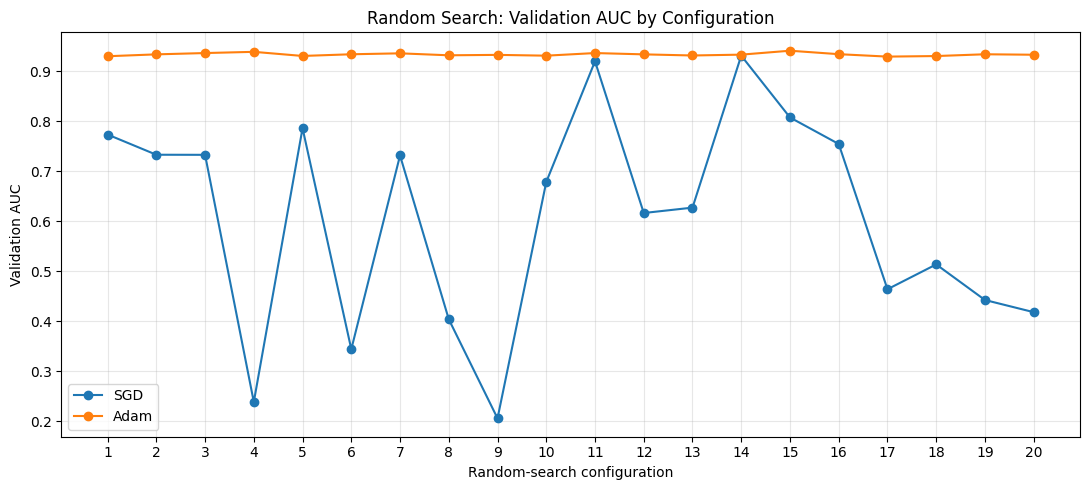

In [72]:
plt.figure(figsize=(11, 5))

for optimizer_name in OPTIMIZERS_TO_TEST:
    subset = tuning_df[tuning_df["Optimizer"] == optimizer_name].sort_values("Configuration")
    plt.plot(
        subset["Configuration"],
        subset["Validation AUC"],
        marker="o",
        label=optimizer_name
    )

plt.xlabel("Random-search configuration")
plt.ylabel("Validation AUC")
plt.title("Random Search: Validation AUC by Configuration")
plt.xticks(config_df["Configuration"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 11. Final evaluation on the test set

Only now do we evaluate the two selected models on the held-out test set. Test results are for final reporting, not for further hyperparameter selection.

In [73]:
final_test_results = []

for _, row in best_rows.iterrows():
    optimizer_name = row["Optimizer"]
    config_id = int(row["Configuration"])
    batch_size = int(row["Batch Size"])

    model = best_models[(config_id, optimizer_name)]

    test_loader_final = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    test_metrics = evaluate_model(model, test_loader_final)

    final_test_results.append({
        "Optimizer": optimizer_name,
        "Configuration": config_id,
        "Learning Rate": row["Learning Rate"],
        "Batch Size": batch_size,
        "Hidden Layers": int(row["Hidden Layers"]),
        "Neurons": int(row["Neurons"]),
        "Best Epoch": int(row["Best Epoch"]),
        "Validation AUC": row["Validation AUC"],
        "Test AUC": test_metrics["AUC"],
        "Test Accuracy": test_metrics["Accuracy"],
        "Test Recall": test_metrics["Recall"]
    })

final_test_df = pd.DataFrame(final_test_results)
display(final_test_df.round(4))

final_test_df.to_csv("hyperparameter_final_test_results.csv", index=False)
print("Saved hyperparameter_final_test_results.csv")

,Optimizer,Configuration,Learning Rate,Batch Size,Hidden Layers,Neurons,Best Epoch,Validation AUC,Test AUC,Test Accuracy,Test Recall
0,Adam,15,0.001,32,4,8,3,0.9413,0.9115,0.4457,0.0000
1,SGD,14,0.010,16,2,64,99,0.9314,0.9385,0.8587,0.8529


Saved hyperparameter_final_test_results.csv


## 12. Compare original and tuned experiments

If you copy `neural_network_experiment_results.csv` from your initial notebook into this notebook's working folder, this cell compares the original best validation-AUC model with the tuned SGD and Adam finalists. If the CSV is not present, the cell safely skips this optional comparison.

In [74]:
original_results_path = "/content/neural_network_experiment_results.csv"

if os.path.exists(original_results_path):
    original_df = pd.read_csv(original_results_path)
    original_best = original_df.loc[original_df["Validation AUC"].idxmax()]

    print("Best original model (selected by validation AUC):")
    display(original_best.to_frame("Value"))

    print("Tuned finalists:")
    display(final_test_df.round(4))
else:
    print(
        "Original results CSV not found. Copy "
        "'neural_network_experiment_results.csv' into this notebook's "
        "working folder to enable the comparison."
    )

Best original model (selected by validation AUC):


,Value
Architecture,3 Hidden Layers
Optimizer,Adam
Best Epoch,6
Train AUC,0.916195
Train Accuracy,0.553663
Train Recall,1.0
Validation AUC,0.938646
Validation Accuracy,0.55102
Validation Recall,1.0
Test AUC,0.931373


Tuned finalists:


,Optimizer,Configuration,Learning Rate,Batch Size,Hidden Layers,Neurons,Best Epoch,Validation AUC,Test AUC,Test Accuracy,Test Recall
0,Adam,15,0.001,32,4,8,3,0.9413,0.9115,0.4457,0.0000
1,SGD,14,0.010,16,2,64,99,0.9314,0.9385,0.8587,0.8529


## Experiment notes

- Random search samples 20 unique configurations from 216 possible combinations.
- Every configuration is evaluated with both SGD and Adam (40 runs maximum).
- Sigmoid activations, Xavier Uniform initialization, zero biases, and BCE loss are held fixed.
- Both optimizers start from identical weights within each configuration.
- The train/validation/test split and preprocessing match the initial notebook.
- Validation AUC selects checkpoints and configurations.
- The test set is evaluated only for the best SGD and best Adam configurations.
- A random search of 20 configurations is a practical first pass, not a guarantee of finding the global optimum.

In [75]:
import torch
import pandas as pd

print("Checking trained model objects...\n")

# Check whether best_models exists
if "best_models" in globals():

    print("best_models FOUND!")
    print("Type:", type(best_models))

    if isinstance(best_models, dict):
        print("\nNumber of stored models:", len(best_models))
        print("\nStored model keys:")

        for key in list(best_models.keys())[:15]:
            print(key)

        # Inspect one stored model
        if len(best_models) > 0:
            first_key = next(iter(best_models))
            print("\nFirst stored model type:")
            print(type(best_models[first_key]))

else:
    print("best_models NOT FOUND in the current runtime.")

# Load the results to identify the winner
results = pd.read_csv(
    "/content/hyperparameter_search_results.csv"
)

best_row = results.loc[
    results["Validation AUC"].idxmax()
]

print("\nWinning configuration:")
display(best_row.to_frame("Value"))

Checking trained model objects...

best_models FOUND!
Type: <class 'dict'>

Number of stored models: 40

Stored model keys:
(1, 'SGD')
(1, 'Adam')
(2, 'SGD')
(2, 'Adam')
(3, 'SGD')
(3, 'Adam')
(4, 'SGD')
(4, 'Adam')
(5, 'SGD')
(5, 'Adam')
(6, 'SGD')
(6, 'Adam')
(7, 'SGD')
(7, 'Adam')
(8, 'SGD')

First stored model type:
<class '__main__.NeuralNetwork'>

Winning configuration:


,Value
Configuration,15
Optimizer,Adam
Learning Rate,0.001
Batch Size,32
Hidden Layers,4
Neurons,8
Best Epoch,3
Epochs Run,18
Training Time (sec),0.727308
Train AUC,0.904639


## Gradient Monitoring plots

Top configurations: [15, 4, 3]


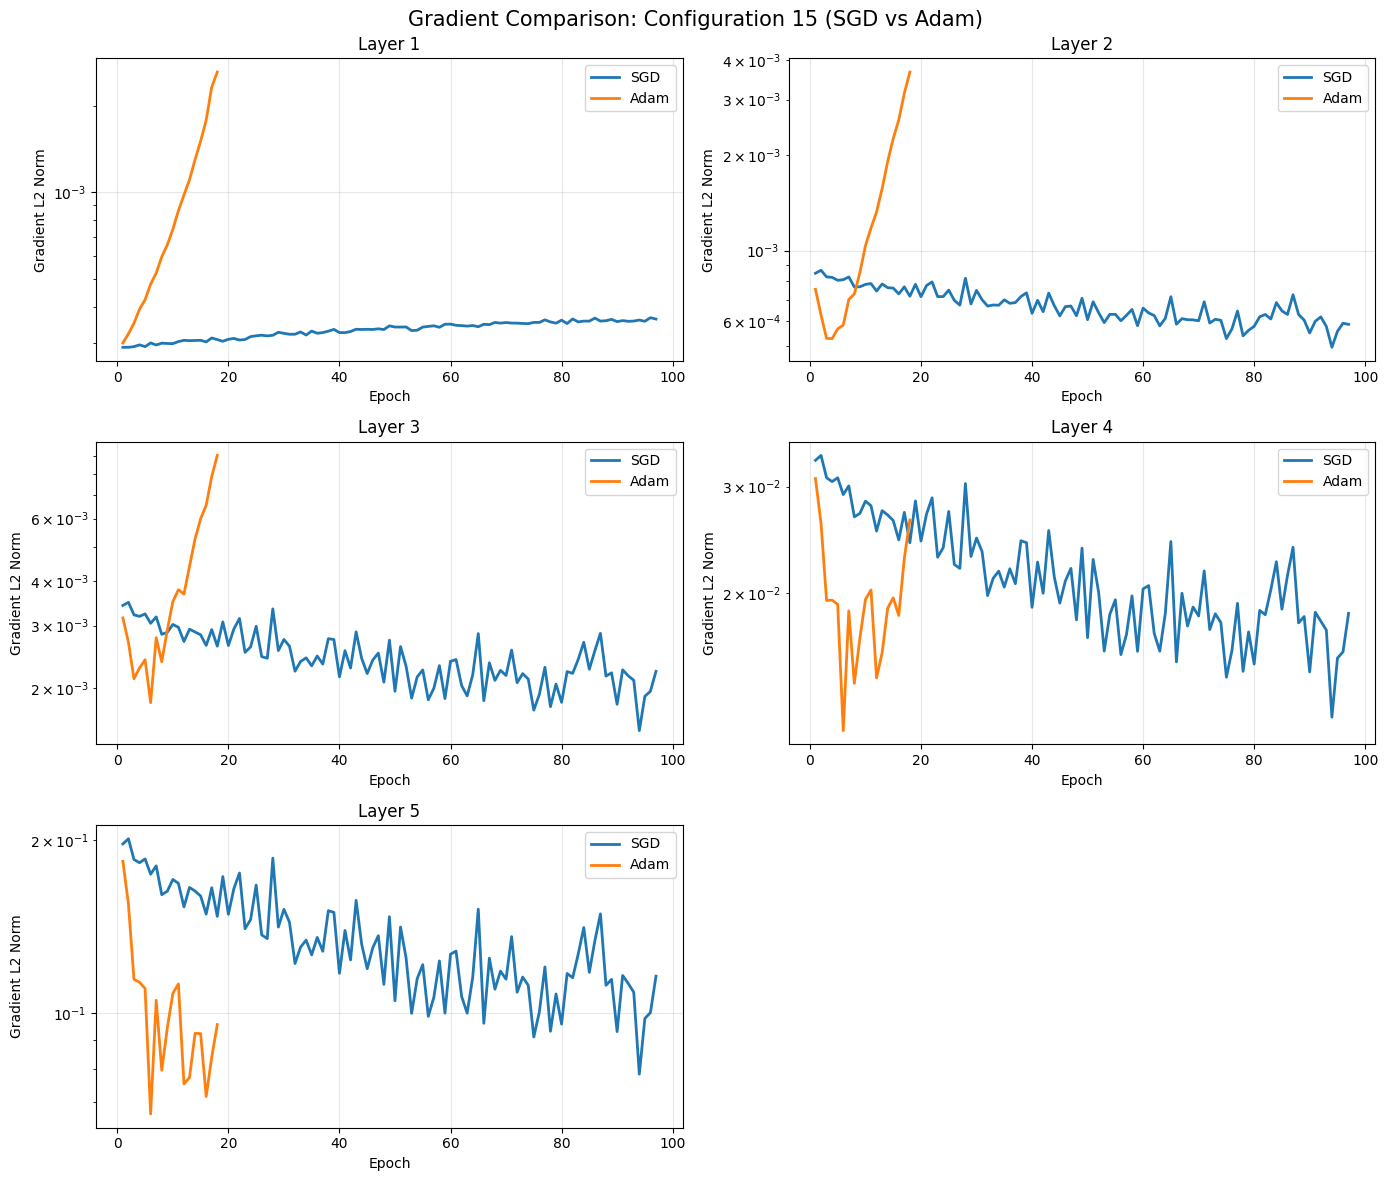

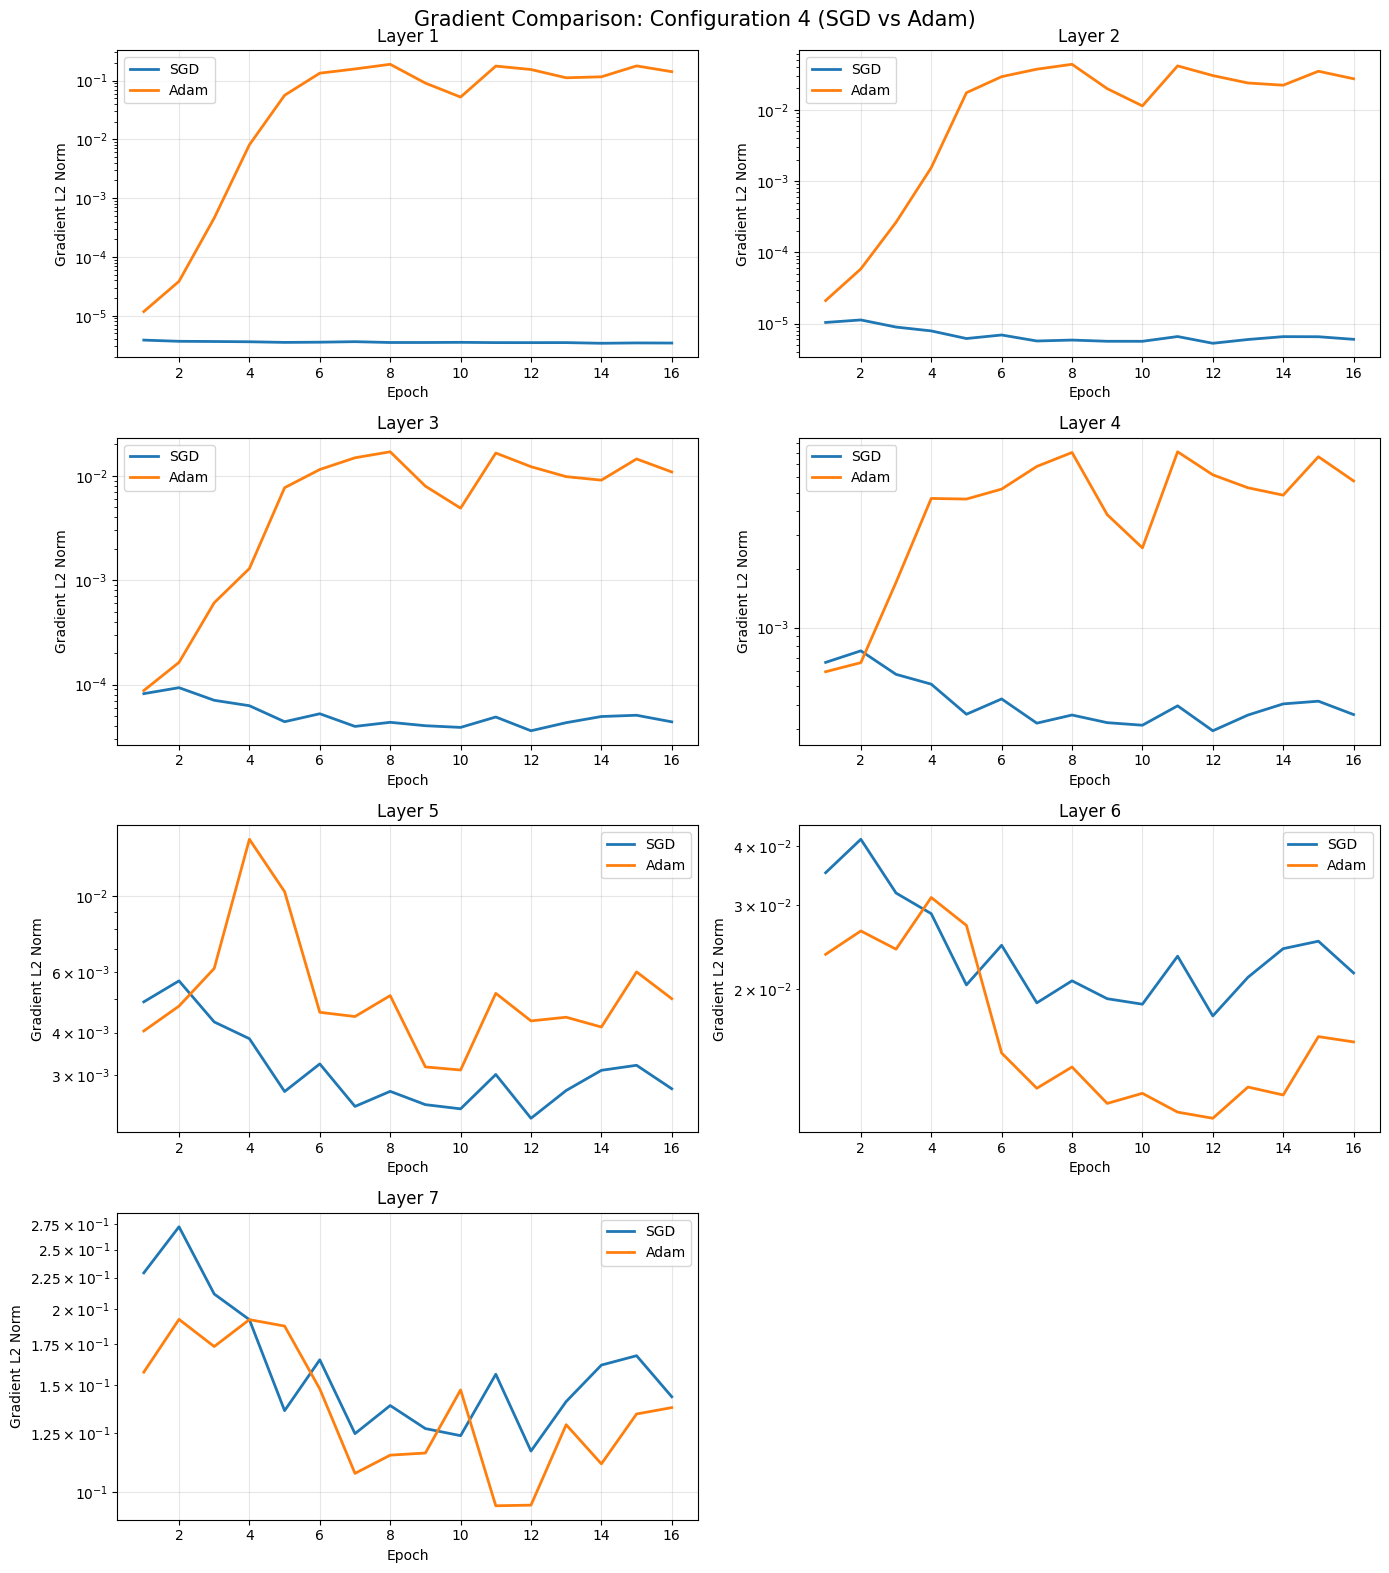

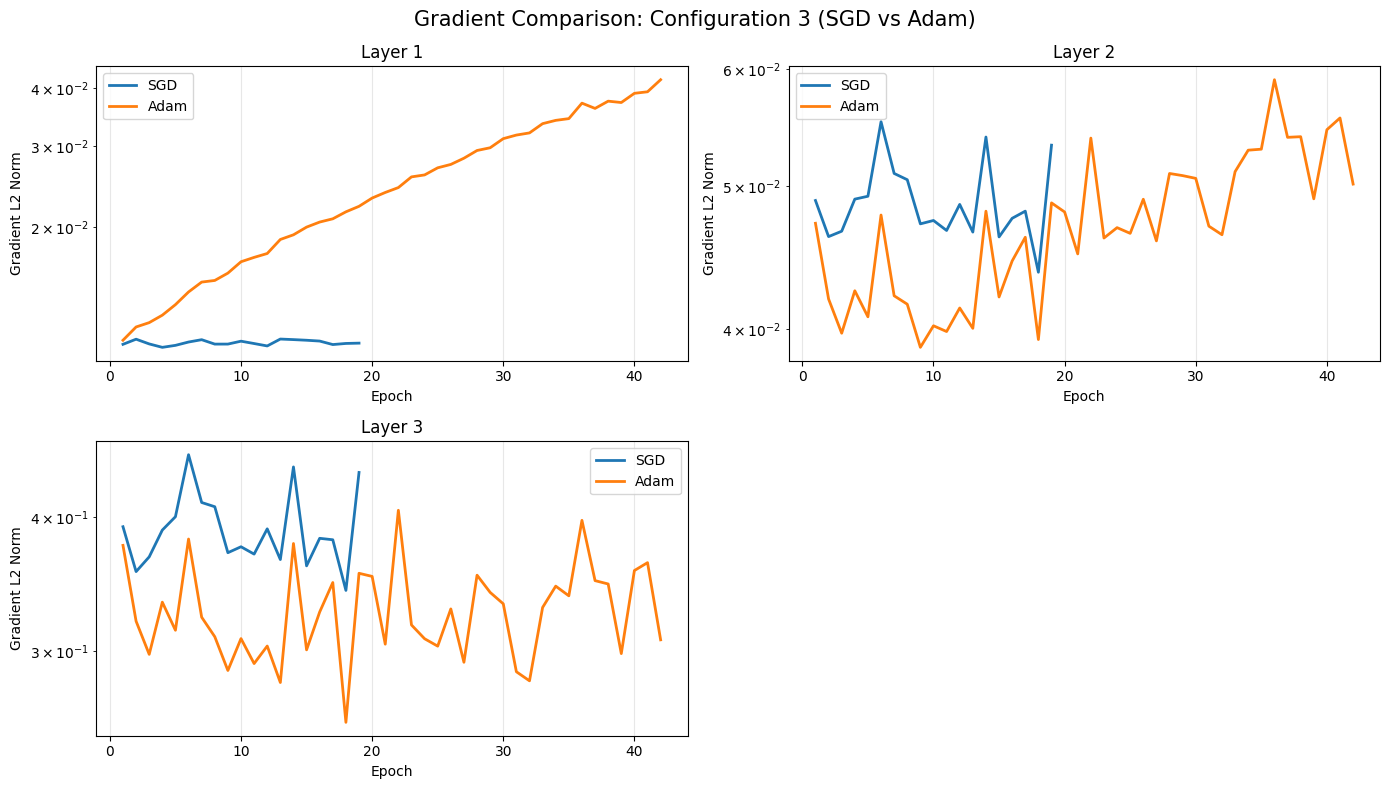

In [76]:

# ==========================================
# GRADIENT LINE PLOTS: TOP 3 CONFIGURATIONS
# SGD vs ADAM
# ==========================================

def get_epoch_gradient_averages(history, layer):

    gradient_history = history["gradient_norms"]

    epoch_averages = []

    for epoch_batches in gradient_history:

        values = [
            batch[layer]
            for batch in epoch_batches
            if layer in batch
            and np.isfinite(batch[layer])
            and batch[layer] > 0
        ]

        epoch_averages.append(
            np.mean(values) if values else np.nan
        )

    return epoch_averages


# Identify top 3 configurations by their best validation AUC
top_configs = (
    tuning_df.groupby("Configuration")["Validation AUC"]
    .max()
    .nlargest(3)
    .index.tolist()
)

print("Top configurations:", top_configs)


for config_id in top_configs:

    sgd_history = tuning_histories[(int(config_id), "SGD")]
    adam_history = tuning_histories[(int(config_id), "Adam")]

    # Get all layers across both optimizers
    layer_names = sorted(
        set(sgd_history["gradient_norms"][0][0].keys()) |
        set(adam_history["gradient_norms"][0][0].keys()),
        key=lambda x: int(x.split("_")[1])
    )

    n_layers = len(layer_names)

    n_cols = 2
    n_rows = int(np.ceil(n_layers / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(14, 4 * n_rows),
        sharex=False
    )

    axes = np.array(axes).flatten()

    for i, layer in enumerate(layer_names):

        ax = axes[i]

        sgd_values = get_epoch_gradient_averages(
            sgd_history, layer
        )

        adam_values = get_epoch_gradient_averages(
            adam_history, layer
        )

        ax.plot(
            range(1, len(sgd_values) + 1),
            sgd_values,
            label="SGD",
            linewidth=2
        )

        ax.plot(
            range(1, len(adam_values) + 1),
            adam_values,
            label="Adam",
            linewidth=2
        )

        ax.set_title(layer.replace("_", " ").title())
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Gradient L2 Norm")

        ax.set_yscale("log")
        ax.grid(True, alpha=0.3)
        ax.legend()

    for j in range(n_layers, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(
        f"Gradient Comparison: Configuration {config_id} (SGD vs Adam)",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


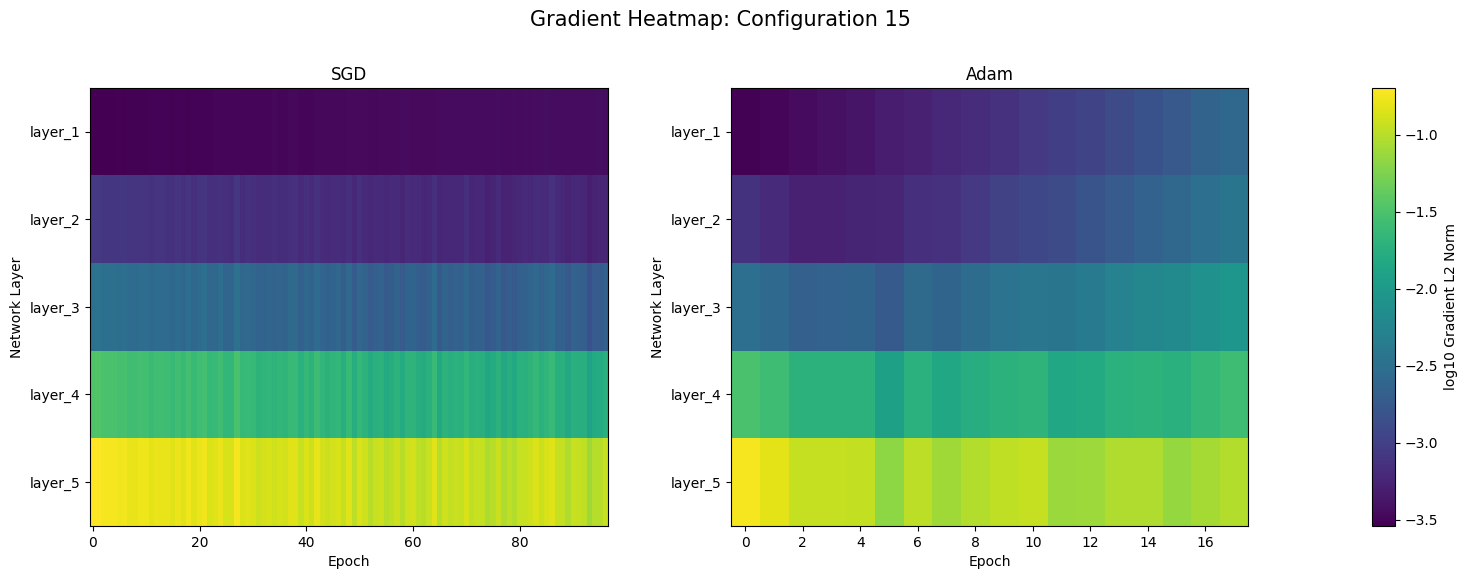

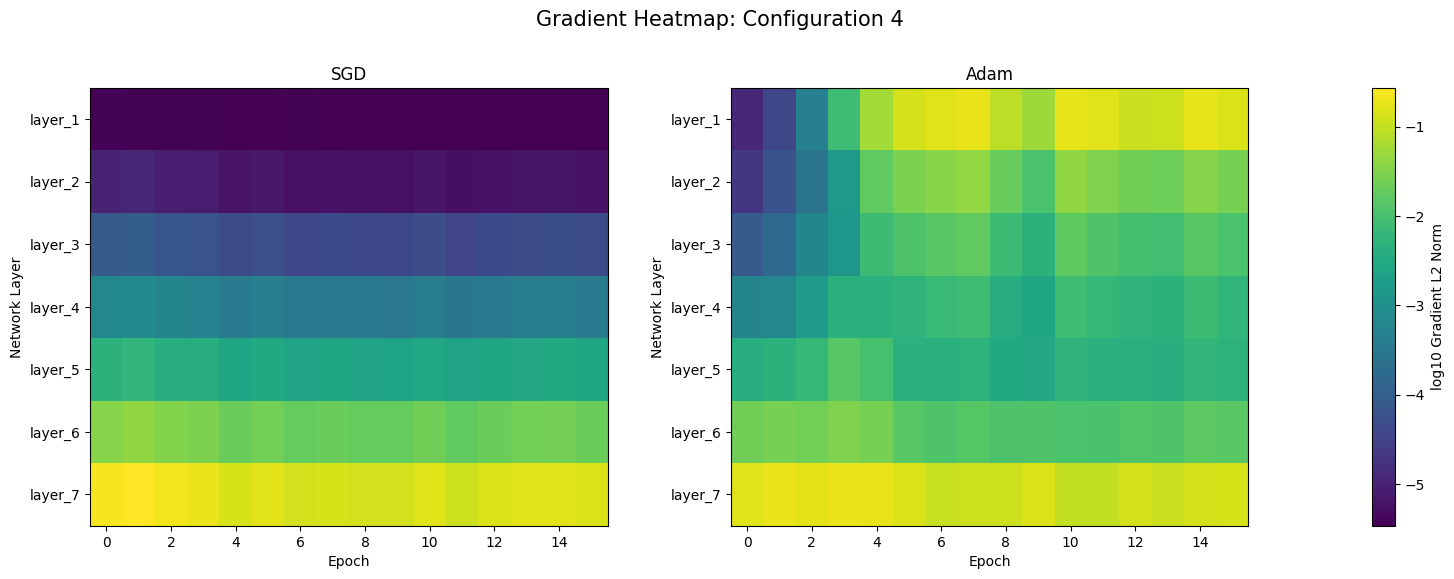

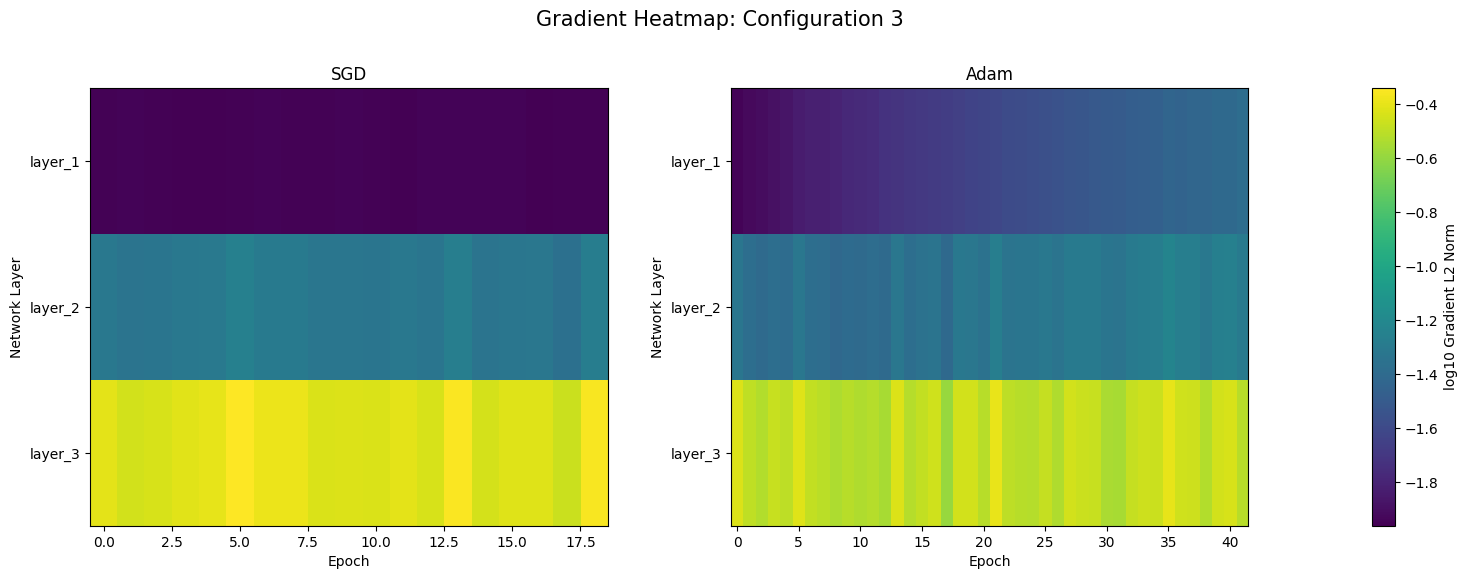

In [89]:

# Generate gradient heatmaps for the top 3 configurations
# Compare SGD vs Adam for each configuration

def build_gradient_matrix(history, layer_names):
    num_epochs = len(history["gradient_norms"])
    matrix = np.full((len(layer_names), num_epochs), np.nan)

    for row, layer in enumerate(layer_names):
        averages = get_epoch_gradient_averages(history, layer)
        matrix[row, :len(averages)] = averages

    return matrix


for config_id in top_configs:

    # Retrieve histories
    sgd_history = tuning_histories[(int(config_id), "SGD")]
    adam_history = tuning_histories[(int(config_id), "Adam")]

    # Get layer names from both optimizers
    layer_names = list(dict.fromkeys(
        get_layer_names(sgd_history) +
        get_layer_names(adam_history)
    ))

    # Build matrices
    sgd_matrix = build_gradient_matrix(sgd_history, layer_names)
    adam_matrix = build_gradient_matrix(adam_history, layer_names)

    # Convert to log10
    sgd_log = np.log10(np.where(sgd_matrix > 0, sgd_matrix, np.nan))
    adam_log = np.log10(np.where(adam_matrix > 0, adam_matrix, np.nan))

    # Shared color scale for fair comparison
    all_values = np.concatenate([
        sgd_log[np.isfinite(sgd_log)],
        adam_log[np.isfinite(adam_log)]
    ])

    if len(all_values) == 0:
        print(f"No valid gradient values for Configuration {config_id}")
        continue

    vmin = np.min(all_values)
    vmax = np.max(all_values)

    # Create figure with dedicated colorbar space
    fig = plt.figure(figsize=(15, 6))

    gs = fig.add_gridspec(
        1, 3,
        width_ratios=[1, 1, 0.045],
        wspace=0.35
    )

    ax_sgd = fig.add_subplot(gs[0, 0])
    ax_adam = fig.add_subplot(gs[0, 1])
    cbar_ax = fig.add_subplot(gs[0, 2])

    # SGD heatmap
    im = ax_sgd.imshow(
        sgd_log,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax_sgd.set_title("SGD")
    ax_sgd.set_xlabel("Epoch")
    ax_sgd.set_ylabel("Network Layer")
    ax_sgd.set_yticks(range(len(layer_names)))
    ax_sgd.set_yticklabels(layer_names)

    # Adam heatmap
    im_adam = ax_adam.imshow(
        adam_log,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax_adam.set_title("Adam")
    ax_adam.set_xlabel("Epoch")
    ax_adam.set_ylabel("Network Layer")
    ax_adam.set_yticks(range(len(layer_names)))
    ax_adam.set_yticklabels(layer_names)

    # Dedicated colorbar
    cbar = fig.colorbar(im_adam, cax=cbar_ax)
    cbar.set_label("log10 Gradient L2 Norm")

    fig.suptitle(
        f"Gradient Heatmap: Configuration {config_id}",
        fontsize=15
    )

    fig.subplots_adjust(
        top=0.85,
        bottom=0.12,
        left=0.08,
        right=0.95
    )

    plt.show()


In [78]:
# Check the layer names stored in one training history
print(tuning_histories[(3, "SGD")]["gradient_norms"][0][0])

{'layer_1': 0.012624290771782398, 'layer_2': 0.04450562596321106, 'layer_3': 0.3539237976074219}
